# Transformer Notebook


## Section 1: Why Attention Is Not Enough
Attention allows tokens to communicate.
We still need a mechanism to transform information.
We still need stable training.

## Section 2: Layer Normalization
Implement normalization manually

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

x = torch.tensor([
    [1.0, 2.0, 3.0],
    [5.0, 10.0, 15.0]
])

# Calculate - See pages 100 - 104
# mean = 0.0 # Expect something ~0
# variance = 0.0 # Expect something ~1
# normalized_output = Object()
mean = x.mean(dim=-1, keepdim=True)
variance = x.var(dim=-1, keepdim=True, unbiased=False)
normalized_output = (x - mean) / torch.sqrt(variance + 1e-5)

print("Mean:\n", mean)
print("Variance:\n", variance)
print("Normalized:\n", normalized_output)

Mean:
 tensor([[ 2.],
        [10.]])
Variance:
 tensor([[ 0.6667],
        [16.6667]])
Normalized:
 tensor([[-1.2247,  0.0000,  1.2247],
        [-1.2247,  0.0000,  1.2247]])


In [2]:
# Verify with
# normalized_output.mean(dim=-1)
# normalized_output.var(dim=-1, unbiased=False)
torch.set_printoptions(sci_mode=False)
print(normalized_output.mean(dim=-1))
print(normalized_output.var(dim=-1, unbiased=False))

tensor([0., 0.])
tensor([1.0000, 1.0000])


## Section 3: Exploring GELU
Compare ReLU and GELU

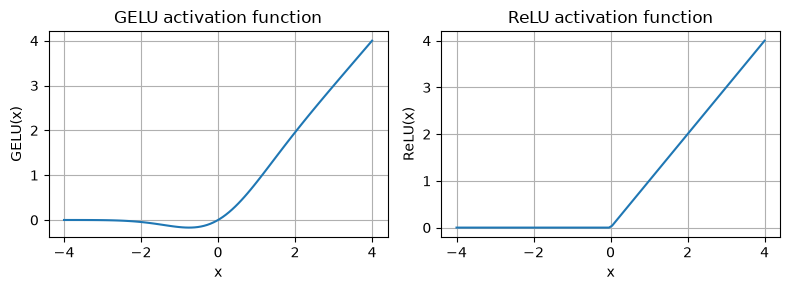

In [3]:
# Use this and plot both
# torch.linspace(-4, 4, 100)
x = torch.linspace(-4, 4, 100)

relu = nn.ReLU()
gelu = nn.GELU(approximate="tanh")

y_relu = relu(x)
y_gelu = gelu(x)

plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)
plt.tight_layout()
plt.show()

## Section 4: Feed Forward Network
Review figure 4.10 in the book

In [4]:
# Create
input_shape = (2, 3, 768)
x = torch.rand(input_shape)
print(x.shape)

torch.Size([2, 3, 768])


In [5]:
# Pass through 
#  Linear - Expect (2,3,768)
print("Input:", x.shape)
linear1 = nn.Linear(768, 4 * 768)
x1 = linear1(x)

#  GELU - Expect (2,3,3072)
x2 = nn.GELU(approximate="tanh")(x1)
print("After Linear + GELU:", x2.shape)

#  Linear again - Expect (2,3,768) again
linear2 = nn.Linear(4 * 768, 768)
x3 = linear2(x2)
print("After second Linear:", x3.shape)

Input: torch.Size([2, 3, 768])
After Linear + GELU: torch.Size([2, 3, 3072])
After second Linear: torch.Size([2, 3, 768])


## Section 5: Residual Connections
Inspect output shapes using a toy network
Compare
 - With residual
 - Without residual

In [6]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[i], layer_sizes[i + 1]), nn.GELU())
            for i in range(len(layer_sizes) - 1)
        ])

    def forward(self, x):
        for layer in self.layers:
            layer_output = layer(x)
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output
        return x


def print_gradients(model, x):
    output = model(x)
    target = torch.tensor([[0.]])
    loss = nn.MSELoss()(output, target)
    loss.backward()
    for name, param in model.named_parameters():
        if "weight" in name:
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")


layer_sizes = [3, 3, 3, 3, 3, 1]
sample_input = torch.tensor([[1., 0., -1.]])

torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut=False)
print("Without residual:")
print("Output shape:", model_without_shortcut(sample_input).shape)
print_gradients(model_without_shortcut, sample_input)

torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut=True)
print("\nWith residual:")
print("Output shape:", model_with_shortcut(sample_input).shape)
print_gradients(model_with_shortcut, sample_input)

x = torch.rand(2, 3, 768)
layer = nn.Linear(768, 768)
output = x + layer(x)
print("\nx + layer(x) shape:", output.shape)

Without residual:
Output shape: torch.Size([1, 1])
layers.0.0.weight has gradient mean of 0.00020174124801997095
layers.1.0.weight has gradient mean of 0.00012011774379061535
layers.2.0.weight has gradient mean of 0.0007152438047342002
layers.3.0.weight has gradient mean of 0.0013988513965159655
layers.4.0.weight has gradient mean of 0.005049603525549173

With residual:
Output shape: torch.Size([1, 1])
layers.0.0.weight has gradient mean of 0.22186799347400665
layers.1.0.weight has gradient mean of 0.20709271728992462
layers.2.0.weight has gradient mean of 0.3292388319969177
layers.3.0.weight has gradient mean of 0.2667771577835083
layers.4.0.weight has gradient mean of 1.3268064260482788

x + layer(x) shape: torch.Size([2, 3, 768])


## Section 6: Connecting Everything
This notebook has walked you through the following process, which is the blueprint for a TransformerBlock
 - Input
 - LayerNorm
 - Attention
 - Add Residual
 - LayerNorm
 - FeedForward
 - Add Residual
 - Output